In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset using whitespace delimiter and specifying no header row
# Prefixed the separator string with 'r' to make it a raw string literal and avoid SyntaxWarnings
df = pd.read_csv('/content/yacht+hydrodynamics.zip', sep=r'\s+', header=None)

# Assign descriptive column names based on the Yacht Hydrodynamics dataset specification
df.columns = [
    'Longitudinal_Position',
    'Prismatic_Coefficient',
    'Length_Displacement_Ratio',
    'Beam_Draught_Ratio',
    'Length_Beam_Ratio',
    'Froude_Number',
    'Residuary_Resistance'
]

print(df.head())

   Longitudinal_Position  Prismatic_Coefficient  Length_Displacement_Ratio  \
0                   -2.3                  0.568                       4.78   
1                   -2.3                  0.568                       4.78   
2                   -2.3                  0.568                       4.78   
3                   -2.3                  0.568                       4.78   
4                   -2.3                  0.568                       4.78   

   Beam_Draught_Ratio  Length_Beam_Ratio  Froude_Number  Residuary_Resistance  
0                3.99               3.17          0.125                  0.11  
1                3.99               3.17          0.150                  0.27  
2                3.99               3.17          0.175                  0.47  
3                3.99               3.17          0.200                  0.78  
4                3.99               3.17          0.225                  1.18  


In [ ]:
print("Shape (rows, columns):", df.shape)
print("\n--- First 5 rows ---")
print(df.head())

print("\n--- Last 5 rows ---")
print(df.tail())

print("\n--- DataFrame Info ---")
print(df.info())

print("\n--- Summary Statistics (describe) ---")
print(df.describe())

Shape (rows, columns): (308, 7)

--- First 5 rows ---
   Longitudinal_Position  Prismatic_Coefficient  Length_Displacement_Ratio  \
0                   -2.3                  0.568                       4.78   
1                   -2.3                  0.568                       4.78   
2                   -2.3                  0.568                       4.78   
3                   -2.3                  0.568                       4.78   
4                   -2.3                  0.568                       4.78   

   Beam_Draught_Ratio  Length_Beam_Ratio  Froude_Number  Residuary_Resistance  
0                3.99               3.17          0.125                  0.11  
1                3.99               3.17          0.150                  0.27  
2                3.99               3.17          0.175                  0.47  
3                3.99               3.17          0.200                  0.78  
4                3.99               3.17          0.225                  1.18

In [ ]:
print("--- Missing Values per Column ---")
print(df.isnull().sum())

print("\nTotal duplicate rows:", df.duplicated().sum())

# Optional: inspect duplicate rows if any exist
if df.duplicated().sum() > 0:
    print(df[df.duplicated(keep=False)])

--- Missing Values per Column ---
Longitudinal_Position        0
Prismatic_Coefficient        0
Length_Displacement_Ratio    0
Beam_Draught_Ratio           0
Length_Beam_Ratio            0
Froude_Number                0
Residuary_Resistance         0
dtype: int64

Total duplicate rows: 0


In [ ]:
# Convert DataFrame to a NumPy array for array-based calculations
data_np = df.to_numpy()

stats_summary = pd.DataFrame({
    "mean": np.mean(data_np, axis=0),
    "median": np.median(data_np, axis=0),
    "min": np.min(data_np, axis=0),
    "max": np.max(data_np, axis=0),
    "std_dev": np.std(data_np, axis=0, ddof=1)  # sample std dev (matches df.std())
}, index=df.columns)

print("--- Summary Statistics via NumPy ---")
print(stats_summary)

largest_std_col = stats_summary["std_dev"].idxmax()
largest_std_val = stats_summary["std_dev"].max()
print(f"\n(2) Measurement with largest standard deviation: {largest_std_col} ({largest_std_val:.4f})")

--- Summary Statistics via NumPy ---
                                mean  median    min    max    std_dev
Longitudinal_Position      -2.381818 -2.3000 -5.000   0.00   1.513219
Prismatic_Coefficient       0.564136  0.5650  0.530   0.60   0.023290
Length_Displacement_Ratio   4.788636  4.7800  4.340   5.14   0.253057
Beam_Draught_Ratio          3.936818  3.9550  2.810   5.35   0.548193
Length_Beam_Ratio           3.206818  3.1500  2.730   3.64   0.247998
Froude_Number               0.287500  0.2875  0.125   0.45   0.100942
Residuary_Resistance       10.495357  3.0650  0.010  62.42  15.160490

(2) Measurement with largest standard deviation: Residuary_Resistance (15.1605)


In [ ]:
top_10_resistance = df.sort_values(by="Residuary_Resistance", ascending=False).head(10)
print("--- Top 10 Records with Highest Residuary Resistance ---")
print(top_10_resistance)

--- Top 10 Records with Highest Residuary Resistance ---
     Longitudinal_Position  Prismatic_Coefficient  Length_Displacement_Ratio  \
223                   -2.3                  0.530                       4.34   
265                    0.0                  0.530                       4.78   
209                   -2.3                  0.530                       4.76   
279                   -5.0                  0.530                       4.78   
139                    0.0                  0.565                       4.77   
195                   -2.3                  0.530                       5.11   
83                    -2.4                  0.568                       4.34   
125                   -2.2                  0.546                       4.78   
167                    0.0                  0.565                       5.10   
27                    -2.3                  0.569                       4.78   

     Beam_Draught_Ratio  Length_Beam_Ratio  Froude_Number  \
2

In [ ]:
# Define explicit Froude number ranges
bins = [-np.inf, 0.25, 0.35, np.inf]
labels = ["Low (<= 0.25)", "Medium (0.25 - 0.35)", "High (> 0.35)"]

# Corrected column name from 'froude_number' to 'Froude_Number'
df["froude_group"] = pd.cut(df["Froude_Number"], bins=bins, labels=labels)

print("--- Count of Records per Froude Group ---")
print(df["froude_group"].value_counts(dropna=False))

print("\n--- Average Residuary Resistance by Froude Group ---")
# Corrected column name from 'residuary_resistance' to 'Residuary_Resistance'
grouped_resistance = df.groupby("froude_group", observed=False)["Residuary_Resistance"].agg(
    count="count",
    mean_resistance="mean",
    median_resistance="median",
    max_resistance="max"
)
print(grouped_resistance)

--- Count of Records per Froude Group ---
froude_group
Low (<= 0.25)           132
Medium (0.25 - 0.35)     88
High (> 0.35)            88
Name: count, dtype: int64

--- Average Residuary Resistance by Froude Group ---
                      count  mean_resistance  median_resistance  \
froude_group                                                      
Low (<= 0.25)           132         0.784167              0.645   
Medium (0.25 - 0.35)     88         4.999318              4.415   
High (> 0.35)            88        30.558182             28.715   

                      max_resistance  
froude_group                          
Low (<= 0.25)                   2.23  
Medium (0.25 - 0.35)           10.36  
High (> 0.35)                  62.42  


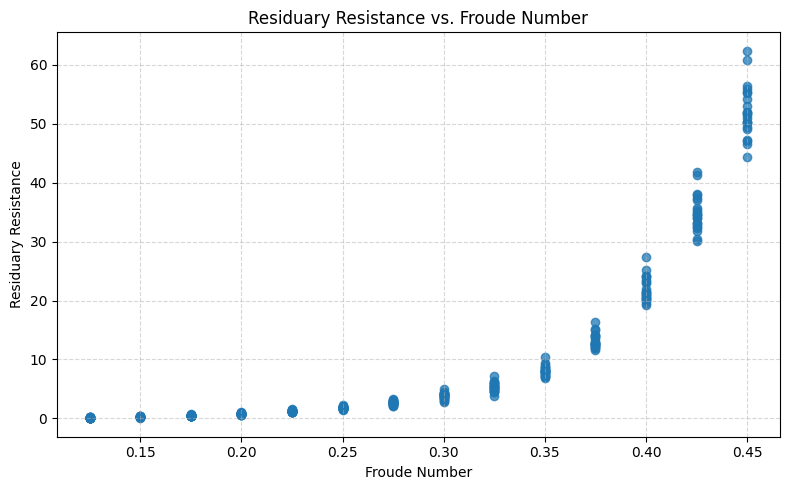

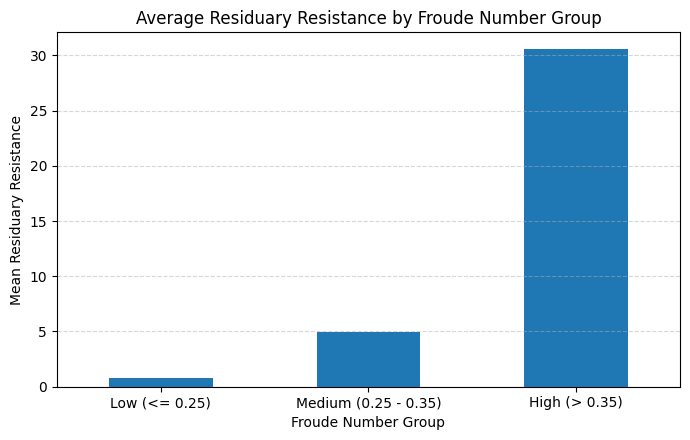

In [ ]:
# Chart 1: Scatter plot of Residuary Resistance vs. Froude Number
plt.figure(figsize=(8, 5))
# Corrected 'froude_number' to 'Froude_Number' and 'residuary_resistance' to 'Residuary_Resistance'
plt.scatter(df["Froude_Number"], df["Residuary_Resistance"], alpha=0.75)
plt.title("Residuary Resistance vs. Froude Number")
plt.xlabel("Froude Number")
plt.ylabel("Residuary Resistance")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Chart 2: Bar chart of Average Residuary Resistance by Froude Group
plt.figure(figsize=(7, 4.5))
grouped_resistance["mean_resistance"].plot(kind="bar")
plt.title("Average Residuary Resistance by Froude Number Group")
plt.xlabel("Froude Number Group")
plt.ylabel("Mean Residuary Resistance")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()